# Réseau de neurones

Le sujet, les données et leur preprocessing, les protocoles et les métriques sont présentés dans `introduction.ipynb`.

L’objectif est de prédire le nombre de locations par heure avec un réseau de neurones multicouche (MLP).

Nous utilisons les données et les découpages définis dans `decoupage.py` pour garder le même protocole que les autres modèles du groupe.

Les variables explicatives et la cible sont standardisées sur l’entraînement de chaque pli. Les prédictions sont ensuite ramenées à leur échelle initiale.

In [1]:
from pathlib import Path

print("Dossier actuel :", Path.cwd())
print("Fichier decoupage.py présent :", Path("decoupage.py").exists())

Dossier actuel : /Users/statealex/Desktop/CS/3A/ml-project
Fichier decoupage.py présent : True


In [2]:
from decoupage import (
    charger_donnees,
    decoupage_daily,
    cv_daily,
    variables,
    CIBLE,
)

# Charger les données 
donnees = charger_donnees()

# Séparer entraînement et test selon le protocole commun
train, test = decoupage_daily(donnees)

# Sélectionner les variables explicatives
colonnes = variables(train)

X_train = train[colonnes]
y_train = train[CIBLE]

X_test = test[colonnes]
y_test = test[CIBLE]

# Préparer les 5 plis de validation croisée communs
splits = cv_daily(train, n_splits=5)

print("Observations d'entraînement :", len(X_train))
print("Observations de test :", len(X_test))
print("Variables explicatives :", len(colonnes))
print("Plis de validation :", len(splits))

Observations d'entraînement : 6785
Observations de test : 1680
Variables explicatives : 25
Plis de validation : 5


In [3]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor

# Normalisation des entrées, puis réseau de neurones
reseau = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(32,),
        activation="relu",
        solver="adam",
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=500,
        early_stopping=False,
        random_state=42,
    ),
)

# Normaliser aussi la cible pour faciliter l'apprentissage
modele = TransformedTargetRegressor(
    regressor=reseau,
    transformer=StandardScaler(),
)

print("Modèle créé, pas encore entraîné.")

Modèle créé, pas encore entraîné.


In [4]:
from sklearn.model_selection import cross_validate

scores = cross_validate(
    modele,
    X_train,
    y_train,
    cv=splits,
    scoring="neg_root_mean_squared_error",
    return_train_score=True,
    n_jobs=1,
)

rmse_train = -scores["train_score"]
rmse_validation = -scores["test_score"]

print(f"RMSE entraînement : {rmse_train.mean():.1f}")
print(f"RMSE validation : {rmse_validation.mean():.1f}")
print(f"Écart-type validation : {rmse_validation.std():.1f}")

RMSE entraînement : 167.7
RMSE validation : 234.9
Écart-type validation : 24.0


## 1. Choix de l’architecture et de la régularisation

Nous comparons trois architectures : une couche de 32 neurones, une couche de 64 neurones et deux couches de 64 et 32 neurones.

Pour chacune, nous testons deux valeurs de régularisation : 0.001 et 0.1. Le choix repose sur la RMSE moyenne des cinq plis de validation du protocole daily.

In [5]:
import pandas as pd

def creer_modele(architecture, alpha):
    reseau = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=architecture,
            activation="relu",
            solver="adam",
            alpha=alpha,
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=False,
            random_state=42,
        ),
    )

    return TransformedTargetRegressor(
        regressor=reseau,
        transformer=StandardScaler(),
    )


resultats = []

for architecture in [(32,), (64,), (64, 32)]:
    for alpha in [0.001, 0.1]:
        modele_candidat = creer_modele(architecture, alpha)

        scores = cross_validate(
            modele_candidat,
            X_train,
            y_train,
            cv=splits,
            scoring="neg_root_mean_squared_error",
            return_train_score=True,
            n_jobs=1,
        )

        resultat = {
            "Architecture": architecture,
            "Alpha": alpha,
            "RMSE train": -scores["train_score"].mean(),
            "RMSE CV": -scores["test_score"].mean(),
            "Écart-type CV": scores["test_score"].std(),
        }

        resultats.append(resultat)

        print(
            f"Architecture {architecture}, alpha={alpha} : "
            f"RMSE CV = {resultat['RMSE CV']:.1f}"
        )

tableau_resultats = (
    pd.DataFrame(resultats)
    .sort_values("RMSE CV")
    .reset_index(drop=True)
)

display(tableau_resultats.round(1))

Architecture (32,), alpha=0.001 : RMSE CV = 234.9


Architecture (32,), alpha=0.1 : RMSE CV = 219.0


Architecture (64,), alpha=0.001 : RMSE CV = 231.6


Architecture (64,), alpha=0.1 : RMSE CV = 215.6


Architecture (64, 32), alpha=0.001 : RMSE CV = 215.6


Architecture (64, 32), alpha=0.1 : RMSE CV = 196.7


,Architecture,Alpha,RMSE train,RMSE CV,Écart-type CV
0,"(64, 32)",0.1,103.9,196.7,18.9
1,"(64, 32)",0.0,92.5,215.6,21.1
2,"(64,)",0.1,149.3,215.6,15.1
3,"(32,)",0.1,167.1,219.0,19.1
4,"(64,)",0.0,141.5,231.6,17.3
5,"(32,)",0.0,167.7,234.9,24.0


In [6]:
display(tableau_resultats.round({
    "Alpha": 3,
    "RMSE train": 1,
    "RMSE CV": 1,
    "Écart-type CV": 1,
}))

,Architecture,Alpha,RMSE train,RMSE CV,Écart-type CV
0,"(64, 32)",0.100,103.9,196.7,18.9
1,"(64, 32)",0.001,92.5,215.6,21.1
2,"(64,)",0.100,149.3,215.6,15.1
3,"(32,)",0.100,167.1,219.0,19.1
4,"(64,)",0.001,141.5,231.6,17.3
5,"(32,)",0.001,167.7,234.9,24.0


Le réseau (64, 32) avec alpha = 0.1 obtient la meilleure RMSE de validation : 196.7 locations/h.

Une régularisation plus forte améliore la validation pour les trois architectures. L’écart entre entraînement et validation reste toutefois important, ce qui indique du surapprentissage.

## 2. Évaluation sur le test daily

Le modèle retenu est entraîné sur toutes les données d’entraînement, puis évalué sur le test.

La RMSE est de 193.4 locations/h, la MAE de 119.8 et le R² de 0.906. Le résultat est proche de celui obtenu en validation.

Le réseau produit 19 prédictions négatives sur 1 680 observations. Les ramener à zéro réduit légèrement la RMSE à 193.2. Les graphiques montrent une bonne correspondance globale, avec quelques erreurs importantes.

In [7]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Choix effectué uniquement avec la validation croisée
modele_final = creer_modele(
    architecture=(64, 32),
    alpha=0.1,
)

# Apprentissage sur toutes les données d'entraînement
modele_final.fit(X_train, y_train)

# Évaluation sur le test réservé
predictions_test = modele_final.predict(X_test)

rmse_test = np.sqrt(mean_squared_error(y_test, predictions_test))
mae_test = mean_absolute_error(y_test, predictions_test)
r2_test = r2_score(y_test, predictions_test)

print(f"RMSE test : {rmse_test:.1f} locations/h")
print(f"MAE test : {mae_test:.1f} locations/h")
print(f"R² test : {r2_test:.3f}")
print(f"Prédictions négatives : {(predictions_test < 0).sum()}")

RMSE test : 193.4 locations/h
MAE test : 119.8 locations/h
R² test : 0.906
Prédictions négatives : 19


Prédiction minimale : -78.0 locations/h
Part de prédictions négatives : 1.1%


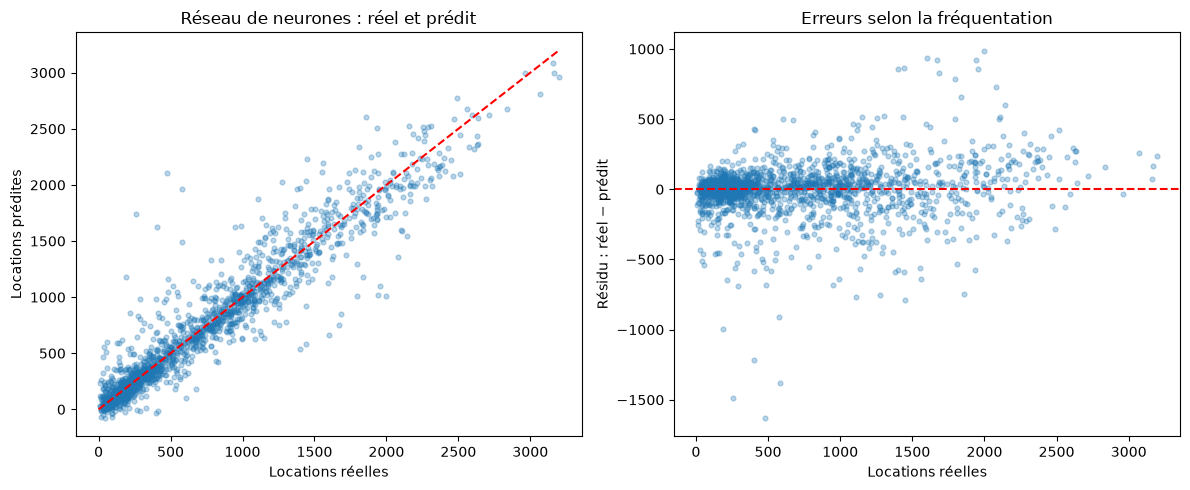

In [8]:
import matplotlib.pyplot as plt

print(f"Prédiction minimale : {predictions_test.min():.1f} locations/h")
print(f"Part de prédictions négatives : {(predictions_test < 0).mean():.1%}")

residus = y_test.to_numpy() - predictions_test

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Comparaison des valeurs réelles et prédites
axes[0].scatter(y_test, predictions_test, alpha=0.3, s=12)

maximum = max(y_test.max(), predictions_test.max())
axes[0].plot([0, maximum], [0, maximum], "r--")

axes[0].set_xlabel("Locations réelles")
axes[0].set_ylabel("Locations prédites")
axes[0].set_title("Réseau de neurones : réel et prédit")

# Erreurs selon le niveau réel de fréquentation
axes[1].scatter(y_test, residus, alpha=0.3, s=12)
axes[1].axhline(0, color="red", linestyle="--")

axes[1].set_xlabel("Locations réelles")
axes[1].set_ylabel("Résidu : réel − prédit")
axes[1].set_title("Erreurs selon la fréquentation")

plt.tight_layout()
plt.show()

In [9]:
# Imposer une prédiction minimale de zéro
predictions_test_corrigees = np.maximum(predictions_test, 0)

bilan_test = pd.DataFrame({
    "Version": ["Prédictions brutes", "Minimum fixé à zéro"],
    "RMSE": [
        rmse_test,
        np.sqrt(mean_squared_error(y_test, predictions_test_corrigees)),
    ],
    "MAE": [
        mae_test,
        mean_absolute_error(y_test, predictions_test_corrigees),
    ],
    "R²": [
        r2_test,
        r2_score(y_test, predictions_test_corrigees),
    ],
})

display(bilan_test.round(3))

,Version,RMSE,MAE,R²
0,Prédictions brutes,193.356,119.778,0.906
1,Minimum fixé à zéro,193.165,119.476,0.907


## 3. Sensibilité à l’initialisation

In [10]:
resultats_stabilite = []

for graine in [42, 123, 456]:
    # Même architecture et même régularisation ;
    # seule l'initialisation aléatoire change.
    reseau = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            alpha=0.1,
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=False,
            random_state=graine,
        ),
    )

    modele_stabilite = TransformedTargetRegressor(
        regressor=reseau,
        transformer=StandardScaler(),
    )

    scores = cross_validate(
        modele_stabilite,
        X_train,
        y_train,
        cv=splits,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
        n_jobs=1,
    )

    resultat = {
        "Graine": graine,
        "RMSE train": -scores["train_score"].mean(),
        "RMSE CV": -scores["test_score"].mean(),
        "Écart-type entre plis": scores["test_score"].std(),
    }

    resultats_stabilite.append(resultat)

    print(
        f"Graine {graine} : "
        f"RMSE CV = {resultat['RMSE CV']:.1f}"
    )

tableau_stabilite = pd.DataFrame(resultats_stabilite)
display(tableau_stabilite.round(1))

Graine 42 : RMSE CV = 196.7


Graine 123 : RMSE CV = 195.3


Graine 456 : RMSE CV = 200.6


,Graine,RMSE train,RMSE CV,Écart-type entre plis
0,42,103.9,196.7,18.9
1,123,104.5,195.3,23.1
2,456,111.0,200.6,18.9



Sur trois initialisations, la RMSE de validation varie de 195.3 à 200.6 locations/h. La variation reste modérée dans ces essais. Nous conservons la graine 42 fixée au départ.

## 4. Courbe d’apprentissage



In [11]:
from sklearn.base import clone

fractions = [0.25, 0.50, 0.75, 1.00]
resultats_apprentissage = []

for numero_pli, (idx_train, idx_val) in enumerate(splits, start=1):

    # Journées disponibles pour l'entraînement de ce pli
    dates_pli = train.iloc[idx_train]["date"]
    jours = dates_pli.unique()

    # Ordre reproductible, identique pour les différentes tailles
    rng = np.random.default_rng(42 + numero_pli)
    jours_melanges = rng.permutation(jours)

    for fraction in fractions:
        nombre_jours = max(1, int(len(jours) * fraction))
        jours_retenus = jours_melanges[:nombre_jours]

        # Garder toutes les heures des journées sélectionnées
        masque = dates_pli.isin(jours_retenus).to_numpy()
        idx_reduits = idx_train[masque]

        # Nouveau réseau avec les réglages déjà fixés
        modele_courbe = clone(modele_final)

        modele_courbe.fit(
            X_train.iloc[idx_reduits],
            y_train.iloc[idx_reduits],
        )

        pred_train = modele_courbe.predict(X_train.iloc[idx_reduits])
        pred_val = modele_courbe.predict(X_train.iloc[idx_val])

        resultats_apprentissage.append({
            "Fraction": fraction,
            "Pli": numero_pli,
            "Jours entraînement": nombre_jours,
            "RMSE train": np.sqrt(mean_squared_error(
                y_train.iloc[idx_reduits], pred_train
            )),
            "RMSE validation": np.sqrt(mean_squared_error(
                y_train.iloc[idx_val], pred_val
            )),
        })

    print(f"Pli {numero_pli}/5 terminé")

details_apprentissage = pd.DataFrame(resultats_apprentissage)

courbe_apprentissage = (
    details_apprentissage.groupby("Fraction")
    .agg(
        jours_moyens=("Jours entraînement", "mean"),
        rmse_train=("RMSE train", "mean"),
        rmse_validation=("RMSE validation", "mean"),
        ecart_type_validation=("RMSE validation", "std"),
    )
    .reset_index()
)

display(courbe_apprentissage.round(1))

Pli 1/5 terminé


Pli 2/5 terminé


Pli 3/5 terminé


Pli 4/5 terminé


Pli 5/5 terminé


,Fraction,jours_moyens,rmse_train,rmse_validation,ecart_type_validation
0,0.2,56.0,76.6,298.2,17.7
1,0.5,113.0,82.4,239.6,19.7
2,0.8,169.4,93.6,208.4,22.0
3,1.0,226.4,103.9,196.7,21.1


La RMSE de validation passe de 298.2 avec environ 56 journées d’entraînement par pli à 196.7 avec 226 journées.

Le réseau profite de l’ajout de données. L’écart avec l’entraînement reste important : davantage de journées pourrait encore améliorer la généralisation.

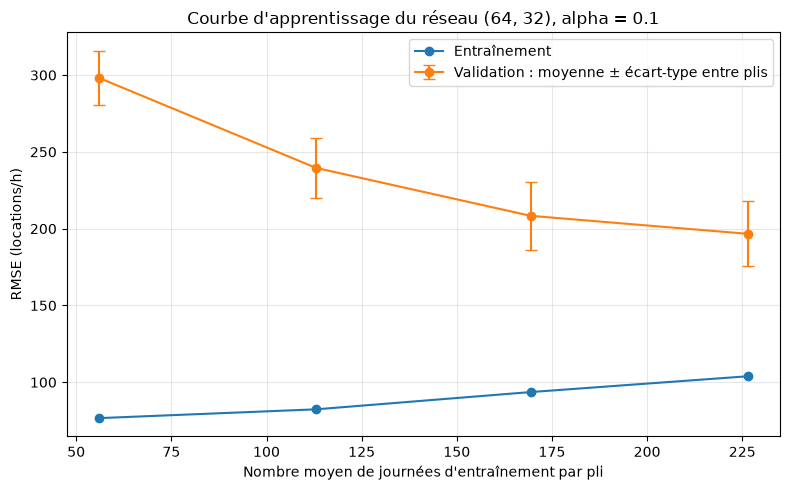

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    courbe_apprentissage["jours_moyens"],
    courbe_apprentissage["rmse_train"],
    "o-",
    label="Entraînement",
)

plt.errorbar(
    courbe_apprentissage["jours_moyens"],
    courbe_apprentissage["rmse_validation"],
    yerr=courbe_apprentissage["ecart_type_validation"],
    fmt="o-",
    capsize=4,
    label="Validation : moyenne ± écart-type entre plis",
)

plt.xlabel("Nombre moyen de journées d'entraînement par pli")
plt.ylabel("RMSE (locations/h)")
plt.title("Courbe d'apprentissage du réseau (64, 32), alpha = 0.1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Apport de la météo



In [13]:
# Variables météo et indicateurs construits à partir de la météo
variables_meteo = [
    "temperature",
    "humidity",
    "wind_speed",
    "visibility",
    "solar_radiation",
    "rainfall",
    "snowfall",
    "is_raining",
    "is_snowing",
]

colonnes_calendrier = [
    col for col in X_train.columns
    if col not in variables_meteo
]

print("Variables conservées :", colonnes_calendrier)

# Même réseau, mêmes plis, mais sans les variables météo
scores_calendrier = cross_validate(
    clone(modele_final),
    X_train[colonnes_calendrier],
    y_train,
    cv=splits,
    scoring="neg_root_mean_squared_error",
    return_train_score=True,
    n_jobs=1,
)

# Référence avec météo : résultat déjà calculé avec la graine 42
reference = tableau_stabilite.loc[
    tableau_stabilite["Graine"] == 42
].iloc[0]

comparaison_meteo = pd.DataFrame({
    "Informations": ["Calendrier seul", "Calendrier + météo"],
    "RMSE train": [
        -scores_calendrier["train_score"].mean(),
        reference["RMSE train"],
    ],
    "RMSE CV": [
        -scores_calendrier["test_score"].mean(),
        reference["RMSE CV"],
    ],
})

display(comparaison_meteo.round(1))

erreur_sans_meteo = comparaison_meteo.loc[0, "RMSE CV"]
erreur_avec_meteo = comparaison_meteo.loc[1, "RMSE CV"]

gain = 100 * (erreur_sans_meteo - erreur_avec_meteo) / erreur_sans_meteo
print(f"Réduction de la RMSE avec la météo : {gain:.1f} %")

Variables conservées : ['hour', 'holiday', 'year', 'month', 'day', 'day_of_week', 'is_weekend', 'is_rush_hour', 'sin_hour', 'cos_hour', 'sin_month', 'cos_month', 'season_Autumn', 'season_Spring', 'season_Summer', 'season_Winter']


,Informations,RMSE train,RMSE CV
0,Calendrier seul,172.2,429.7
1,Calendrier + météo,103.9,196.7


Réduction de la RMSE avec la météo : 54.2 %


À architecture et réglages identiques, la RMSE de validation passe de 429.7 avec le calendrier seul à 196.7 avec le calendrier et la météo, soit une réduction de 54.2 %.

La météo apporte donc une information prédictive importante. Cette comparaison ne mesure pas un effet causal et utilise la météo observée.

## 6. Évaluation temporelle

Nous conservons le réseau choisi sur daily pour étudier ses performances sur des périodes futures.

La validation temporelle donne une RMSE moyenne de 306.9, avec de fortes variations entre périodes.

Sur le test de septembre à novembre, avec réentraînement progressif, la RMSE globale est de 218.0, la MAE de 146.5 et le R² de 0.868. Le réseau retrouve le rythme journalier, mais reproduit moins précisément certains pics.

Cette analyse est exploratoire : l’architecture a été choisie avec le protocole daily. Elle utilise également la météo observée.

In [14]:
from decoupage import decoupage_temporal, cv_temporal

# Découpage temporel commun au groupe
train_temporel, test_temporel = decoupage_temporal(donnees)

colonnes_temporelles = variables(train_temporel)

X_train_temporel = train_temporel[colonnes_temporelles]
y_train_temporel = train_temporel[CIBLE]

# Plis chronologiques : passé pour apprendre,
# période suivante pour valider
splits_temporels = cv_temporal(train_temporel)

print(
    "Entraînement :",
    train_temporel["date"].min().date(),
    "→",
    train_temporel["date"].max().date(),
)

print(
    "Test réservé :",
    test_temporel["date"].min().date(),
    "→",
    test_temporel["date"].max().date(),
)

print("Nombre de plis temporels :", len(splits_temporels))

Entraînement : 2017-12-01 → 2018-09-10
Test réservé : 2018-09-11 → 2018-11-30
Nombre de plis temporels : 23


In [15]:
resultats_temporels = []

for numero, (idx_train, idx_val) in enumerate(
    splits_temporels, start=1
):
    modele_pli = creer_modele(
        architecture=(64, 32),
        alpha=0.1,
    )

    modele_pli.fit(
        X_train_temporel.iloc[idx_train],
        y_train_temporel.iloc[idx_train],
    )

    predictions = modele_pli.predict(
        X_train_temporel.iloc[idx_val]
    )

    rmse = np.sqrt(mean_squared_error(
        y_train_temporel.iloc[idx_val],
        predictions,
    ))

    dates_validation = train_temporel.iloc[idx_val]["date"]

    resultats_temporels.append({
        "Pli": numero,
        "Début validation": dates_validation.min(),
        "Fin validation": dates_validation.max(),
        "Nombre d'heures": len(idx_val),
        "RMSE": rmse,
    })

    print(
        f"Pli {numero}/{len(splits_temporels)} : "
        f"RMSE = {rmse:.1f}"
    )

tableau_temporel = pd.DataFrame(resultats_temporels)

display(tableau_temporel.round({"RMSE": 1}))

print(
    "RMSE moyenne des périodes :",
    round(tableau_temporel["RMSE"].mean(), 1),
)

Pli 1/23 : RMSE = 280.8


Pli 2/23 : RMSE = 276.9


Pli 3/23 : RMSE = 254.8


Pli 4/23 : RMSE = 284.4


Pli 5/23 : RMSE = 260.2


Pli 6/23 : RMSE = 312.2


... (15 outputs left out)

Pli 22/23 : RMSE = 372.7


Pli 23/23 : RMSE = 304.2


,Pli,Début validation,Fin validation,Nombre d'heures,RMSE
0,1,2018-04-01,2018-04-07,168,280.8
1,2,2018-04-08,2018-04-15,168,276.9
2,3,2018-04-16,2018-04-22,168,254.8
3,4,2018-04-23,2018-04-29,168,284.4
4,5,2018-04-30,2018-05-06,168,260.2
5,6,2018-05-07,2018-05-14,168,312.2
6,7,2018-05-15,2018-05-21,168,272.8
7,8,2018-05-22,2018-05-28,168,247.8
8,9,2018-05-29,2018-06-04,168,564.8
9,10,2018-06-05,2018-06-11,168,413.2


RMSE moyenne des périodes : 306.9


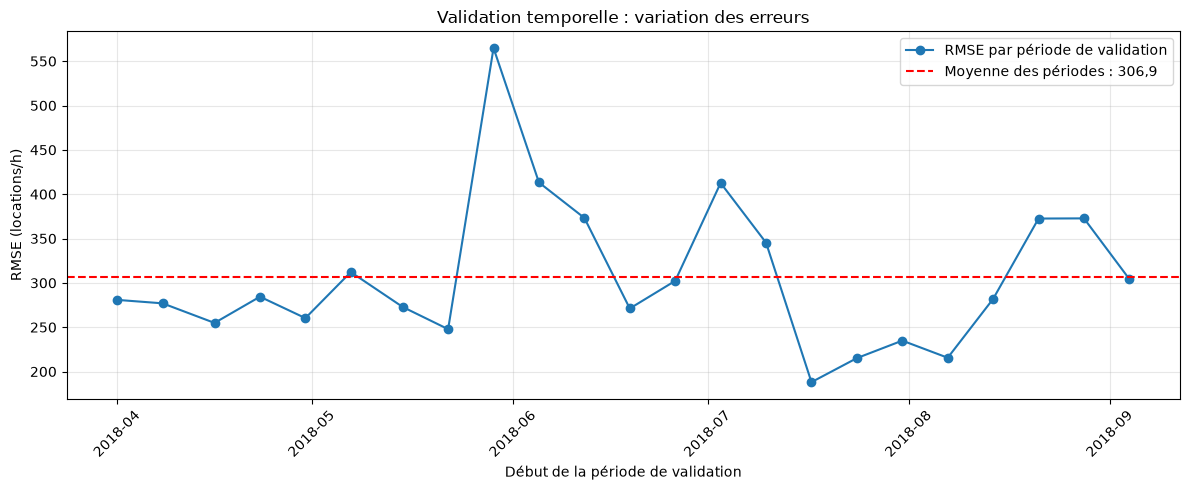

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(
    tableau_temporel["Début validation"],
    tableau_temporel["RMSE"],
    "o-",
    label="RMSE par période de validation",
)

plt.axhline(
    tableau_temporel["RMSE"].mean(),
    color="red",
    linestyle="--",
    label="Moyenne des périodes : 306,9",
)

plt.xlabel("Début de la période de validation")
plt.ylabel("RMSE (locations/h)")
plt.title("Validation temporelle : variation des erreurs")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
from decoupage import walk_forward

predictions_temporelles = []
bilans_periodes = []

for passe, periode in walk_forward(train_temporel, test_temporel):
    modele_periode = creer_modele(
        architecture=(64, 32),
        alpha=0.1,
    )

    modele_periode.fit(
        passe[colonnes_temporelles],
        passe[CIBLE],
    )

    # Scores bruts, comme pour la validation temporelle
    predictions = modele_periode.predict(
        periode[colonnes_temporelles]
    )

    detail = periode[["date", "hour", CIBLE]].copy()
    detail["prediction"] = predictions
    predictions_temporelles.append(detail)

    rmse = np.sqrt(mean_squared_error(
        periode[CIBLE], predictions
    ))

    bilans_periodes.append({
        "Début": periode["date"].min(),
        "Fin": periode["date"].max(),
        "RMSE": rmse,
    })

    print(
        f"Période du {periode['date'].min().date()} : "
        f"RMSE = {rmse:.1f}"
    )

predictions_temporelles = pd.concat(
    predictions_temporelles,
    ignore_index=True,
)

reel_temporel = predictions_temporelles[CIBLE]
predit_temporel = predictions_temporelles["prediction"]

print("\nRésultats globaux sur le test temporel :")
print(
    f"RMSE : "
    f"{np.sqrt(mean_squared_error(reel_temporel, predit_temporel)):.1f}"
)
print(
    f"MAE : "
    f"{mean_absolute_error(reel_temporel, predit_temporel):.1f}"
)
print(
    f"R² : "
    f"{r2_score(reel_temporel, predit_temporel):.3f}"
)

Période du 2018-09-11 : RMSE = 190.6


Période du 2018-09-20 : RMSE = 327.0


Période du 2018-09-27 : RMSE = 320.1


Période du 2018-10-08 : RMSE = 183.9


Période du 2018-10-16 : RMSE = 147.4


Période du 2018-10-23 : RMSE = 209.9


Période du 2018-10-30 : RMSE = 197.3


Période du 2018-11-08 : RMSE = 215.9


Période du 2018-11-16 : RMSE = 168.1


Période du 2018-11-23 : RMSE = 148.2

Résultats globaux sur le test temporel :
RMSE : 218.0
MAE : 146.5
R² : 0.868


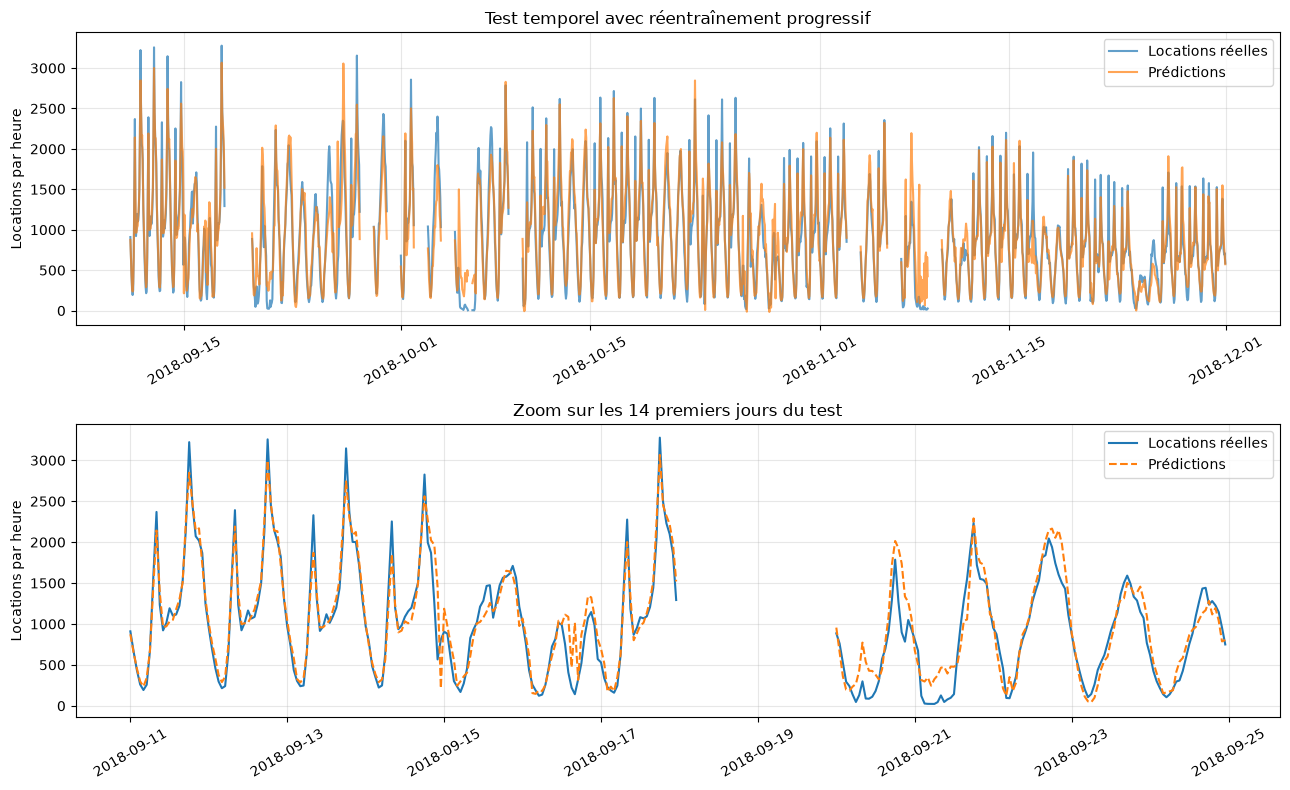

In [18]:
# Construire les dates et heures exactes
chronique = predictions_temporelles.copy()

chronique["instant"] = (
    pd.to_datetime(chronique["date"])
    + pd.to_timedelta(chronique["hour"], unit="h")
)

chronique = chronique.sort_values("instant").set_index("instant")

# Réintroduire les heures absentes pour laisser des trous
# dans le graphique lorsque le service était fermé
index_complet = pd.date_range(
    chronique.index.min(),
    chronique.index.max(),
    freq="h",
)

chronique = chronique.reindex(index_complet)

fig, axes = plt.subplots(2, 1, figsize=(13, 8))

# Toute la période de test
axes[0].plot(
    chronique.index, chronique[CIBLE],
    label="Locations réelles", alpha=0.7,
)
axes[0].plot(
    chronique.index, chronique["prediction"],
    label="Prédictions", alpha=0.7,
)
axes[0].set_title("Test temporel avec réentraînement progressif")

# Zoom fixé sur les 14 premiers jours calendaires
zoom = chronique.loc[
    chronique.index < chronique.index.min() + pd.Timedelta(days=14)
]

axes[1].plot(
    zoom.index, zoom[CIBLE],
    label="Locations réelles",
)
axes[1].plot(
    zoom.index, zoom["prediction"],
    label="Prédictions", linestyle="--",
)
axes[1].set_title("Zoom sur les 14 premiers jours du test")

for ax in axes:
    ax.set_ylabel("Locations par heure")
    ax.legend()
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## Limites

Le réseau conserve un écart important entre entraînement et validation. Les résultats portent sur une seule année et ne garantissent pas une généralisation à d’autres années.

Le prétraitement commun calcule les seuils de winsorisation avant le découpage. Ce point doit être corrigé, puis les expériences relancées pour obtenir des scores sans cette fuite de données.